# MobileNetV3-Large — phân loại 8 lớp bệnh/khỏe mạnh trên cây dâu

**Notebook tự chứa mã nguồn:** không cần tải thêm file Python.
Chạy trên Kaggle/Colab có GPU, lần lượt từ trên xuống. Chỉ sửa cell **Cấu hình**.

Dùng đúng tám lớp từ script bạn gửi, chia train/val/test 70/15/15, huấn luyện head rồi
fine-tune, chọn checkpoint bằng validation và đánh giá test sau cùng.

Chưa có dữ liệu ảnh hoặc model được huấn luyện kèm theo. Tất cả kết quả sẽ sinh ra từ
bộ ảnh của bạn khi chạy, không có kết quả thực nghiệm mẫu được điền sẵn.

**Trước khi chạy:** kiểm tra nhãn. Ảnh cắt/augment từ cùng một ảnh gốc hoặc ảnh cùng cây
nên có `groups.csv` để giữ cùng tập. Hash pixel chỉ ngăn ảnh trùng hoàn toàn, không nhận
ra mọi ảnh gần trùng. Không gộp lại test chính thức nếu cần đánh giá theo split chính thức.

## 1. Kiểm tra thư viện
Chỉ cài các gói còn thiếu; không chủ động nâng cấp TensorFlow/Keras đang có. Cần mạng để cài gói/tải trọng số ImageNet lần đầu.

In [1]:
import importlib.util
import subprocess
import sys
from pathlib import Path

packages = {
    "tensorflow": "tensorflow>=2.16,<3",
    "numpy": "numpy>=1.26,<3",
    "sklearn": "scikit-learn>=1.4,<2",
    "PIL": "Pillow>=10.3,<13",
    "matplotlib": "matplotlib>=3.8,<4",
}
missing = [spec for module, spec in packages.items() if importlib.util.find_spec(module) is None]
if missing:
    subprocess.run([sys.executable, "-m", "pip", "install", *missing], check=True)

import tensorflow as tf
print("Python:", sys.version.split()[0])
print("TensorFlow:", tf.__version__)
print("GPU:", tf.config.list_physical_devices("GPU"))
if not tf.config.list_physical_devices("GPU"):
    print("CHÚ Ý: đang không có GPU. Bật GPU trước khi huấn luyện để tránh phải chạy lâu trên CPU.")


Python: 3.12.13
TensorFlow: 2.20.0
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU'), PhysicalDevice(name='/physical_device:GPU:1', device_type='GPU')]


## 2. Tạo file chương trình
Cell dài này chứa toàn bộ mã nguồn. Chạy nguyên cell, không cần sửa.

In [2]:
WORK_DIR = Path("/kaggle/working") if Path("/kaggle/working").exists() else (
    Path("/content") if Path("/content").exists() else Path.cwd()
)
SCRIPT_PATH = WORK_DIR / "strawberry_mobilenetv3.py"
SCRIPT_SOURCE = '#!/usr/bin/env python3\n"""MobileNetV3-Large: phân loại 7 bệnh dâu tây và lớp healthy.\n\nLệnh:\n  python strawberry_mobilenetv3.py split --data-dir DATA --split-dir SPLIT\n  python strawberry_mobilenetv3.py train --split-dir SPLIT --output-dir OUTPUT\n  python strawberry_mobilenetv3.py predict --model OUTPUT/best_model.keras \\\n      --labels OUTPUT/class_names.json --image anh.jpg\n\nDựa trên bố cục lớp và quy trình TensorFlow/Keras trong script người dùng gửi.\nBổ sung: kiểm tra ảnh, loại ảnh trùng pixel, nhóm nguồn tùy chọn, manifest,\nchọn checkpoint bằng validation, đánh giá test, biểu đồ và xuất TFLite.\nKhông có ảnh, trọng số huấn luyện hay số liệu thực nghiệm được đóng gói sẵn.\n\nTài liệu API:\nhttps://www.tensorflow.org/api_docs/python/tf/keras/applications/MobileNetV3Large\nhttps://keras.io/guides/transfer_learning/\nhttps://scikit-learn.org/stable/modules/cross_validation.html\nhttps://scikit-learn.org/stable/modules/generated/sklearn.metrics.classification_report.html\nhttps://ai.google.dev/edge/litert/models/post_training_float16_quant\n"""\nfrom __future__ import annotations\n\nimport argparse\nimport csv\nimport hashlib\nimport importlib.metadata\nimport json\nimport math\nimport os\nimport random\nimport sys\nimport time\nimport warnings\nfrom collections import Counter, defaultdict\nfrom pathlib import Path\nfrom typing import Any, Sequence\n\nimport numpy as np\nfrom PIL import Image, ImageOps\n\n# Thứ tự này được lưu cùng model; KHÔNG tự đổi thứ tự khi triển khai ứng dụng.\nCLASS_NAMES = sorted([\n    "angular_leafspot", "anthracnose_fruit_rot", "blossom_blight",\n    "gray_mold", "healthy", "leaf_spot",\n    "powdery_mildew_fruit", "powdery_mildew_leaf",\n])\nLABELS_VI = {\n    "angular_leafspot": "Đốm lá góc cạnh",\n    "anthracnose_fruit_rot": "Thán thư trên quả",\n    "blossom_blight": "Cháy hoa",\n    "gray_mold": "Mốc xám",\n    "healthy": "Khỏe mạnh",\n    "leaf_spot": "Đốm lá",\n    "powdery_mildew_fruit": "Phấn trắng trên quả",\n    "powdery_mildew_leaf": "Phấn trắng trên lá",\n}\nIMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff", ".webp"}\nSPLITS = ("train", "val", "test")\nMANIFEST_COLUMNS = [\n    "split", "class_name", "class_id", "relative_path", "source_relative_path",\n    "group_id", "pixel_sha256", "file_sha256", "width", "height",\n]\n\n\ndef write_json(path: Path, value: Any) -> None:\n    path.write_text(json.dumps(value, ensure_ascii=False, indent=2, allow_nan=False),\n                    encoding="utf-8")\n\n\ndef write_csv(path: Path, rows: Sequence[dict], columns: Sequence[str]) -> None:\n    # utf-8-sig giúp các phần mềm bảng tính đọc tiếng Việt đúng.\n    with path.open("w", newline="", encoding="utf-8-sig") as f:\n        writer = csv.DictWriter(f, fieldnames=list(columns), extrasaction="ignore")\n        writer.writeheader()\n        writer.writerows(rows)\n\n\ndef read_csv(path: Path) -> list[dict[str, str]]:\n    with path.open(newline="", encoding="utf-8-sig") as f:\n        return list(csv.DictReader(f))\n\n\ndef sha256_file(path: Path) -> str:\n    digest = hashlib.sha256()\n    with path.open("rb") as f:\n        for block in iter(lambda: f.read(1024 * 1024), b""):\n            digest.update(block)\n    return digest.hexdigest()\n\n\ndef open_rgb(path: Path) -> Image.Image:\n    """Sửa hướng EXIF, giải mã đầy đủ và chuyển RGB; không sửa file gốc."""\n    with Image.open(path) as image:\n        if getattr(image, "n_frames", 1) > 1:\n            raise ValueError("Ảnh nhiều frame: cần chọn frame phù hợp trước khi dùng.")\n        image.load()\n        return ImageOps.exif_transpose(image).convert("RGB")\n\n\ndef pixel_hash(image: Image.Image) -> str:\n    # So sánh đúng từng pixel ở độ phân giải gốc, KHÔNG phải perceptual hash.\n    digest = hashlib.sha256(f"RGB:{image.width}:{image.height}:".encode())\n    digest.update(image.tobytes())\n    return digest.hexdigest()\n\n\ndef ensure_new_directory(path: Path) -> None:\n    if path.exists() and any(path.iterdir()):\n        raise ValueError(\n            f"Thư mục đã có dữ liệu: {path}\\n"\n            "Không ghi đè hoặc tự dùng lại kết quả cũ. Hãy chọn đường dẫn mới. "\n            "Để dùng split đã tạo, chạy lệnh train, không chạy lại split."\n        )\n    path.mkdir(parents=True, exist_ok=True)\n\n\ndef find_dataset_roots(search_root: str | Path, max_depth: int = 5) -> list[str]:\n    """Tìm thư mục CHA chứa trực tiếp đủ 8 folder lớp. Không tự chọn khi mơ hồ."""\n    search_root = Path(search_root).expanduser()\n    if not search_root.exists():\n        return []\n    found: list[str] = []\n    for current, dirs, _ in os.walk(search_root):\n        dirs[:] = [d for d in dirs if not d.startswith(".") and d != "__MACOSX"]\n        depth = len(Path(current).relative_to(search_root).parts)\n        if set(CLASS_NAMES).issubset(dirs):\n            found.append(str(Path(current).resolve()))\n            dirs[:] = []\n        elif depth >= max_depth:\n            dirs[:] = []\n    return sorted(set(found))\n\n\ndef read_group_map(path: Path | None) -> dict[str, str]:\n    """CSV: relative_path,group_id. Cùng ảnh gốc/cây/phiên chụp => cùng group."""\n    if path is None:\n        return {}\n    rows = read_csv(path)\n    if not rows or not {"relative_path", "group_id"}.issubset(rows[0]):\n        raise ValueError("groups.csv phải có hai cột relative_path,group_id và có dữ liệu.")\n    mapping = {}\n    for row in rows:\n        rel = row["relative_path"].strip().replace("\\\\", "/")\n        gid = row["group_id"].strip()\n        if not rel or not gid or rel in mapping:\n            raise ValueError(f"Dòng groups.csv rỗng hoặc trùng relative_path: {row}")\n        mapping[rel] = gid\n    return mapping\n\n\nclass UnionFind:\n    """Gộp nhóm nguồn khi phát hiện cùng ảnh đã được gán hai group khác nhau."""\n    def __init__(self) -> None:\n        self.parent: dict[str, str] = {}\n\n    def find(self, value: str) -> str:\n        self.parent.setdefault(value, value)\n        root = value\n        while self.parent[root] != root:\n            root = self.parent[root]\n        while value != root:\n            parent = self.parent[value]\n            self.parent[value] = root\n            value = parent\n        return root\n\n    def union(self, first: str, second: str) -> None:\n        a, b = self.find(first), self.find(second)\n        if a != b:\n            small, large = sorted([a, b])\n            self.parent[large] = small\n\n\ndef allocate_counts(n: int, ratios: Sequence[float]) -> np.ndarray:\n    """Làm tròn theo phần dư lớn nhất, đảm bảo mỗi split có ít nhất một ảnh."""\n    if n < 3:\n        raise ValueError("Mỗi lớp cần ít nhất 3 ảnh hợp lệ, không trùng để chia 3 tập.")\n    target = n * np.asarray(ratios, dtype=float)\n    counts = np.floor(target).astype(int)\n    order = np.argsort(-(target - counts), kind="stable")\n    for idx in order[:n - int(counts.sum())]:\n        counts[idx] += 1\n    for idx in np.flatnonzero(counts == 0):\n        donor = int(np.argmax(counts))\n        counts[donor] -= 1\n        counts[idx] += 1\n    return counts\n\n\ndef stratified_split(records: list[dict], ratios: Sequence[float], seed: int) -> None:\n    """Chia RIÊNG từng lớp. Không cân bằng số ảnh các lớp bằng cách nhân bản."""\n    rng = random.Random(seed)\n    for name in CLASS_NAMES:\n        selected = [r for r in records if r["class_name"] == name]\n        rng.shuffle(selected)\n        counts = allocate_counts(len(selected), ratios)\n        start = 0\n        for split_name, count in zip(SPLITS, counts):\n            for row in selected[start:start + int(count)]:\n                row["split"] = split_name\n            start += int(count)\n\n\ndef grouped_split(records: list[dict], ratios: Sequence[float], seed: int) -> None:\n    """Tìm holdout theo NHÓM gần tỷ lệ mong muốn; không tách một nhóm qua 2 tập.\n\n    Tối ưu dựa trên số mẫu/nhãn, không dùng dự đoán hay kết quả model.\n    Tỷ lệ khi chia nhóm là xấp xỉ, không đảm bảo đúng 70/15/15 từng lớp.\n    """\n    from sklearn.model_selection import GroupShuffleSplit\n    y = np.asarray([int(r["class_id"]) for r in records])\n    groups = np.asarray([r["group_id"] for r in records])\n    indices = np.arange(len(records))\n    k = len(CLASS_NAMES)\n    totals = np.bincount(y, minlength=k)\n    for cls in range(k):\n        if len(set(groups[y == cls])) < 3:\n            raise ValueError(f"Lớp {CLASS_NAMES[cls]} có dưới 3 nhóm nguồn độc lập. "\n                             "Không thể đặt lớp này vào cả train, val, test mà không rò rỉ.")\n\n    def score(parts: Sequence[np.ndarray]) -> float:\n        fractions = np.asarray([np.bincount(y[p], minlength=k) / totals for p in parts])\n        return float(np.mean((fractions - np.asarray(ratios)[:, None]) ** 2))\n\n    test_candidates = []\n    splitter = GroupShuffleSplit(n_splits=256, test_size=ratios[2], random_state=seed)\n    for train_val, test in splitter.split(indices, y, groups):\n        if np.any(np.bincount(y[test], minlength=k) == 0):\n            continue\n        if any(len(set(groups[train_val][y[train_val] == c])) < 2 for c in range(k)):\n            continue\n        discrepancy = np.mean((np.bincount(y[test], minlength=k) / totals - ratios[2]) ** 2)\n        test_candidates.append((float(discrepancy), train_val, test))\n    test_candidates.sort(key=lambda item: item[0])\n    best = None\n    best_score = math.inf\n    for candidate_index, (_, train_val, test) in enumerate(test_candidates[:16]):\n        val_ratio = ratios[1] / (ratios[0] + ratios[1])\n        val_splitter = GroupShuffleSplit(n_splits=128, test_size=val_ratio,\n                                        random_state=seed + 1 + candidate_index)\n        for tr_local, val_local in val_splitter.split(train_val, y[train_val], groups[train_val]):\n            train, val = train_val[tr_local], train_val[val_local]\n            if any(np.any(np.bincount(y[p], minlength=k) == 0) for p in (train, val)):\n                continue\n            current = score((train, val, test))\n            if current < best_score:\n                best_score, best = current, (train.copy(), val.copy(), test.copy())\n    if best is None:\n        raise ValueError("Không tìm được phép chia nhóm có đủ 8 lớp trong cả 3 tập. "\n                         "Hãy kiểm tra group_id, tăng số nhóm độc lập hoặc đổi tỷ lệ.")\n    for name, positions in zip(SPLITS, best):\n        for position in positions:\n            records[int(position)]["split"] = name\n\n\ndef plot_split_counts(count_rows: list[dict], output: Path) -> None:\n    import matplotlib\n    matplotlib.use("Agg")\n    import matplotlib.pyplot as plt\n    fig, ax = plt.subplots(figsize=(12, 6))\n    x = np.arange(len(count_rows))\n    for i, split in enumerate(SPLITS):\n        ax.bar(x + (i - 1) * 0.25, [r[split] for r in count_rows], 0.25, label=split)\n    ax.set_xticks(x, [r["class_name"] for r in count_rows], rotation=40, ha="right")\n    ax.set_ylabel("Number of unique valid images")\n    ax.set_title("Dataset split by class")\n    ax.legend()\n    fig.tight_layout()\n    fig.savefig(output, dpi=180)\n    plt.close(fig)\n\n\ndef prepare_dataset(data_dir: str | Path, split_dir: str | Path,\n                    ratios: Sequence[float] = (0.70, 0.15, 0.15), seed: int = 42,\n                    group_csv: str | Path | None = None) -> dict:\n    data_root = Path(data_dir).expanduser().resolve()\n    destination = Path(split_dir).expanduser().resolve()\n    ratios = tuple(float(r) for r in ratios)\n    if len(ratios) != 3 or any(r <= 0 for r in ratios) or not np.isclose(sum(ratios), 1):\n        raise ValueError("Tỷ lệ phải gồm 3 số dương có tổng bằng 1.")\n    if not data_root.is_dir():\n        raise FileNotFoundError(f"Không thấy thư mục dữ liệu: {data_root}")\n    if destination == data_root or data_root in destination.parents or destination in data_root.parents:\n        raise ValueError("DATA_DIR và SPLIT_DIR phải là hai thư mục tách biệt, không lồng nhau.")\n    missing = [c for c in CLASS_NAMES if not (data_root / c).is_dir()]\n    if missing:\n        raise ValueError(f"DATA_DIR phải là thư mục CHA của 8 lớp. Thiếu: {missing}")\n    ensure_new_directory(destination)\n    group_map = read_group_map(Path(group_csv).expanduser().resolve() if group_csv else None)\n    union = UnionFind()\n    records, duplicates, invalid, ignored = [], [], [], []\n    seen: dict[str, dict] = {}\n    source_counts = Counter()\n    n_scanned = 0\n    label_conflicts = False\n    print(f"\\nĐang kiểm tra ảnh tại {data_root}", flush=True)\n    for class_id, name in enumerate(CLASS_NAMES):\n        candidates = sorted(p for p in (data_root / name).rglob("*") if p.is_file())\n        for path in candidates:\n            relative = path.relative_to(data_root).as_posix()\n            if any(part.startswith(".") for part in path.relative_to(data_root).parts):\n                continue\n            if path.suffix.lower() not in IMAGE_EXTENSIONS:\n                ignored.append({"source_relative_path": relative, "reason": "unsupported extension"})\n                continue\n            n_scanned += 1\n            source_counts[name] += 1\n            try:\n                rgb = open_rgb(path)\n                digest = pixel_hash(rgb)\n                width, height = rgb.size\n                rgb.close()\n            except (OSError, ValueError, Image.DecompressionBombError) as exc:\n                invalid.append({"source_relative_path": relative, "reason": str(exc)})\n                continue\n            if group_csv and relative not in group_map:\n                raise ValueError(f"groups.csv thiếu ảnh hợp lệ: {relative}")\n            group = group_map[relative] if group_csv else digest\n            union.find(group)\n            row = {"class_name": name, "class_id": class_id,\n                   "source_relative_path": relative, "pixel_sha256": digest,\n                   "group_id": group, "width": width, "height": height}\n            if digest in seen:\n                previous = seen[digest]\n                conflict = name != previous["class_name"]\n                label_conflicts |= conflict\n                duplicates.append({\n                    "source_relative_path": relative,\n                    "kept_source": previous["source_relative_path"],\n                    "class_name": name, "kept_class": previous["class_name"],\n                    "action": "CONFLICT: different labels" if conflict else "removed exact pixel duplicate",\n                })\n                union.union(group, previous["group_id"])\n            else:\n                seen[digest] = row\n                records.append(row)\n            if n_scanned % 200 == 0:\n                print(f"  Đã kiểm tra {n_scanned} ảnh...", flush=True)\n    write_csv(destination / "invalid_images.csv", invalid, ["source_relative_path", "reason"])\n    write_csv(destination / "ignored_files.csv", ignored, ["source_relative_path", "reason"])\n    write_csv(destination / "duplicates.csv", duplicates,\n              ["source_relative_path", "kept_source", "class_name", "kept_class", "action"])\n    if label_conflicts:\n        raise ValueError(f"Cùng ảnh có nhãn khác nhau. Xem {destination / \'duplicates.csv\'}; "\n                         "sửa nhãn nguồn rồi chạy lại với SPLIT_DIR mới.")\n    for row in records:\n        row["group_id"] = union.find(row["group_id"])\n    for name in CLASS_NAMES:\n        count = sum(r["class_name"] == name for r in records)\n        if count < 3:\n            raise ValueError(f"Lớp {name} chỉ có {count} ảnh hợp lệ, không trùng; cần ít nhất 3.")\n        if count < 20:\n            warnings.warn(f"{name}: chỉ {count} ảnh không trùng. Kết quả test lớp này sẽ rất thiếu ổn định.")\n    if group_csv:\n        grouped_split(records, ratios, seed)\n    else:\n        stratified_split(records, ratios, seed)\n    for split in SPLITS:\n        for name in CLASS_NAMES:\n            (destination / split / name).mkdir(parents=True, exist_ok=True)\n    print("Đang ghi các bản PNG RGB; ảnh gốc được giữ nguyên...", flush=True)\n    for i, row in enumerate(records):\n        source = data_root / row["source_relative_path"]\n        # Filename là hash pixel đầy đủ: tránh trùng tên file từ các thư mục con.\n        relative = f"{row[\'split\']}/{row[\'class_name\']}/{row[\'pixel_sha256\']}.png"\n        target = destination / relative\n        rgb = open_rgb(source)\n        if pixel_hash(rgb) != row["pixel_sha256"]:\n            raise RuntimeError(f"Ảnh nguồn thay đổi giữa quá trình chia: {source}")\n        rgb.save(target, format="PNG")\n        rgb.close()\n        row["relative_path"] = relative\n        row["file_sha256"] = sha256_file(target)\n        if (i + 1) % 200 == 0:\n            print(f"  Đã ghi {i + 1}/{len(records)} ảnh...", flush=True)\n    records.sort(key=lambda r: (SPLITS.index(r["split"]), r["class_id"], r["relative_path"]))\n    write_csv(destination / "manifest.csv", records, MANIFEST_COLUMNS)\n    write_json(destination / "class_names.json", CLASS_NAMES)\n    (destination / "labels.txt").write_text("\\n".join(CLASS_NAMES) + "\\n", encoding="utf-8")\n    counts = []\n    for name in CLASS_NAMES:\n        part_counts = {s: sum(r["class_name"] == name and r["split"] == s for r in records) for s in SPLITS}\n        counts.append({"class_name": name, "source_image_files": source_counts[name],\n                       "total_unique_valid": sum(part_counts.values()), **part_counts})\n    write_csv(destination / "split_counts.csv", counts,\n              ["class_name", "source_image_files", "total_unique_valid", *SPLITS])\n    fingerprint = hashlib.sha256(json.dumps(\n        [(r["source_relative_path"], r["pixel_sha256"], r["group_id"], r["split"]) for r in records],\n        ensure_ascii=False).encode("utf-8")).hexdigest()\n    info = {\n        "complete": True, "version": 1, "data_root": str(data_root), "seed": seed,\n        "requested_ratios": dict(zip(SPLITS, ratios)), "group_aware": bool(group_csv),\n        "class_names": CLASS_NAMES, "total_original_image_files": n_scanned,\n        "total_unique_valid_images": len(records), "invalid_images_removed": len(invalid),\n        "exact_pixel_duplicates_removed": len(duplicates), "ignored_files": len(ignored),\n        "dataset_fingerprint": fingerprint,\n        "manifest_sha256": sha256_file(destination / "manifest.csv"),\n        "image_storage": "lossless RGB PNG, EXIF-corrected, original resolution",\n        "actual_counts": {s: sum(r["split"] == s for r in records) for s in SPLITS},\n        "limitations": "Exact pixel deduplication is not near-duplicate detection. "\n                       "Without groups.csv, related photos/crops may still cross splits.",\n    }\n    write_json(destination / "split_info.json", info)\n    load_split(destination, verify_files=True)\n    plot_split_counts(counts, destination / "split_distribution.png")\n    print("\\nSố ảnh thực tế sau kiểm tra và loại trùng:")\n    for row in counts:\n        print(f"{row[\'class_name\']:25s} train={row[\'train\']:5d}  val={row[\'val\']:5d}  test={row[\'test\']:5d}")\n    print(f"\\nHoàn tất: {destination}\\nẢnh lỗi: {len(invalid)}; ảnh trùng loại bỏ: {len(duplicates)}.")\n    if not group_csv:\n        print("LƯU Ý: chưa có group_id; chưa bảo đảm các ảnh gần trùng/cùng cây ở cùng split.")\n    return info\n\n\ndef load_split(split_dir: str | Path, verify_files: bool = True) -> tuple[list[dict], list[str], dict]:\n    root = Path(split_dir).expanduser().resolve()\n    info_path = root / "split_info.json"\n    if not info_path.is_file():\n        raise ValueError("Split chưa hoàn tất/không đúng định dạng. Chạy lệnh split trước.")\n    info = json.loads(info_path.read_text(encoding="utf-8"))\n    if not info.get("complete"):\n        raise ValueError("Split không có trạng thái hoàn tất.")\n    if sha256_file(root / "manifest.csv") != info["manifest_sha256"]:\n        raise ValueError("manifest.csv đã bị thay đổi; không tự dùng lại split không khớp.")\n    names = json.loads((root / "class_names.json").read_text(encoding="utf-8"))\n    if names != info["class_names"] or names != CLASS_NAMES:\n        raise ValueError("Thứ tự/tên lớp không khớp với cấu hình 8 lớp.")\n    records = read_csv(root / "manifest.csv")\n    paths_seen, pixels_seen = set(), set()\n    group_splits: dict[str, set[str]] = defaultdict(set)\n    counts = Counter()\n    for row in records:\n        row["class_id"] = int(row["class_id"])\n        cls, split, relative = row["class_name"], row["split"], row["relative_path"]\n        if split not in SPLITS or not (0 <= row["class_id"] < len(names)) or names[row["class_id"]] != cls:\n            raise ValueError("Manifest có nhãn/split không hợp lệ.")\n        path = (root / relative).resolve()\n        if root not in path.parents or tuple(Path(relative).parts[:2]) != (split, cls):\n            raise ValueError(f"Đường dẫn không thuộc split/class dự kiến: {relative}")\n        if relative in paths_seen or row["pixel_sha256"] in pixels_seen:\n            raise ValueError("Phát hiện ảnh/đường dẫn trùng trong manifest.")\n        paths_seen.add(relative)\n        pixels_seen.add(row["pixel_sha256"])\n        group_splits[row["group_id"]].add(split)\n        counts[(split, cls)] += 1\n        if not path.is_file():\n            raise FileNotFoundError(path)\n        if verify_files and sha256_file(path) != row["file_sha256"]:\n            raise ValueError(f"Ảnh split bị thay đổi: {path}")\n    if any(len(parts) > 1 for parts in group_splits.values()):\n        raise ValueError("Rò rỉ group_id giữa các tập.")\n    if any(counts[(s, c)] == 0 for s in SPLITS for c in names):\n        raise ValueError("Có lớp thiếu ảnh trong một trong 3 split.")\n    for split in SPLITS:\n        actual = {p.relative_to(root).as_posix() for p in (root / split).rglob("*") if p.is_file()}\n        expected = {r["relative_path"] for r in records if r["split"] == split}\n        if actual != expected:\n            raise ValueError(f"File thực tế ở {split} không khớp manifest. Không tự thêm/bớt ảnh sau chia.")\n    return records, names, info\n\n\ndef tensorflow_setup(seed: int = 42, threads: int = 4, deterministic: bool = True):\n    os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "2")\n    os.environ.setdefault("TF_NUM_INTRAOP_THREADS", str(threads))\n    os.environ.setdefault("TF_NUM_INTEROP_THREADS", str(max(1, threads // 2)))\n    try:\n        import tensorflow as tf\n    except ImportError as exc:\n        raise RuntimeError("Chưa có TensorFlow. Cài thư viện theo README hoặc dùng notebook GPU có TensorFlow.") from exc\n    tf.keras.utils.set_random_seed(seed)\n    try:\n        tf.config.threading.set_intra_op_parallelism_threads(threads)\n        tf.config.threading.set_inter_op_parallelism_threads(max(1, threads // 2))\n        for gpu in tf.config.list_physical_devices("GPU"):\n            tf.config.experimental.set_memory_growth(gpu, True)\n    except RuntimeError:\n        pass  # Runtime đã khởi tạo, ví dụ khi gọi lại trong notebook.\n    if deterministic:\n        tf.config.experimental.enable_op_determinism()\n    return tf\n\n\ndef make_dataset(tf, records: list[dict], root: Path, image_size: int, batch_size: int,\n                 training: bool, seed: int, threads: int, augment: bool = True):\n    paths = [str(root / r["relative_path"]) for r in records]\n    labels = np.asarray([r["class_id"] for r in records], dtype=np.int32)\n    dataset = tf.data.Dataset.from_tensor_slices((paths, labels))\n    if training:\n        dataset = dataset.shuffle(len(paths), seed=seed, reshuffle_each_iteration=True)\n\n    def decode(path, label):\n        image = tf.io.decode_png(tf.io.read_file(path), channels=3)\n        image = tf.image.resize(tf.cast(image, tf.float32), [image_size, image_size], method="bilinear")\n        image = tf.ensure_shape(image, [image_size, image_size, 3])\n        # include_preprocessing=True: giữ pixel [0,255], KHÔNG chia 255 lần nữa.\n        return image, label\n\n    dataset = dataset.map(decode, num_parallel_calls=threads, deterministic=True)\n    dataset = dataset.batch(batch_size, drop_remainder=False)\n    if training and augment:\n        # Augmentation nằm ngoài model xuất ra; chỉ áp dụng trên TRAIN.\n        augmentation = tf.keras.Sequential([\n            tf.keras.layers.RandomFlip("horizontal_and_vertical", seed=seed),\n            tf.keras.layers.RandomRotation(0.10, fill_mode="reflect", seed=seed + 1),\n            tf.keras.layers.RandomZoom(0.10, fill_mode="reflect", seed=seed + 2),\n            tf.keras.layers.RandomContrast(0.10, seed=seed + 3),\n            tf.keras.layers.RandomBrightness(0.10, value_range=(0, 255), seed=seed + 4),\n        ], name="train_only_augmentation")\n        dataset = dataset.map(\n            lambda x, y: (tf.clip_by_value(augmentation(x, training=True), 0.0, 255.0), y),\n            num_parallel_calls=1, deterministic=True,\n        )\n    options = tf.data.Options()\n    options.deterministic = True\n    options.threading.private_threadpool_size = threads\n    options.threading.max_intra_op_parallelism = 1\n    # Không cache toàn bộ ảnh float32 vào RAM.\n    return dataset.with_options(options).prefetch(2)\n\n\ndef build_model(tf, image_size: int, num_classes: int, weights: str = "imagenet"):\n    chosen_weights = None if weights.lower() == "none" else weights\n    if chosen_weights is None:\n        warnings.warn("Đang dùng trọng số ngẫu nhiên, KHÔNG phải học chuyển giao ImageNet. Chỉ dùng để debug.")\n    try:\n        backbone = tf.keras.applications.MobileNetV3Large(\n            input_shape=(image_size, image_size, 3),\n            alpha=1.0, minimalistic=False,\n            include_top=False, weights=chosen_weights,\n            pooling="avg", include_preprocessing=True,\n        )\n    except Exception as exc:\n        raise RuntimeError("Không tải/khởi tạo được MobileNetV3-Large. Kiểm tra Internet hoặc đường dẫn weights. "\n                           "Code KHÔNG tự chuyển sang trọng số ngẫu nhiên.") from exc\n    backbone.trainable = False\n    inputs = tf.keras.Input(shape=(image_size, image_size, 3), dtype=tf.float32, name="image_rgb")\n    features = backbone(inputs, training=False)  # Giữ thống kê BatchNorm khi fine-tune.\n    features = tf.keras.layers.Dropout(0.30, name="classifier_dropout")(features)\n    outputs = tf.keras.layers.Dense(num_classes, activation="softmax", dtype="float32",\n                                    name="disease_probabilities")(features)\n    model = tf.keras.Model(inputs, outputs, name="strawberry_mobilenetv3_large")\n    return model, backbone\n\n\ndef compile_model(tf, model, learning_rate: float) -> None:\n    model.compile(\n        optimizer=tf.keras.optimizers.Adam(learning_rate=learning_rate),\n        loss=tf.keras.losses.SparseCategoricalCrossentropy(),\n        metrics=[tf.keras.metrics.SparseCategoricalAccuracy(name="accuracy")],\n        jit_compile=False,\n    )\n\n\ndef plot_training_history(rows: list[dict], output: Path, head_epochs: int) -> None:\n    import matplotlib\n    matplotlib.use("Agg")\n    import matplotlib.pyplot as plt\n    for metric, label in [("accuracy", "Accuracy"), ("loss", "Cross-entropy loss")]:\n        fig, ax = plt.subplots(figsize=(8, 5))\n        epoch_numbers = [r["epoch"] for r in rows]\n        ax.plot(epoch_numbers, [r[metric] for r in rows], label="train")\n        ax.plot(epoch_numbers, [r[f"val_{metric}"] for r in rows], label="validation")\n        if len(rows) > head_epochs:\n            ax.axvline(head_epochs + 0.5, linestyle="--", label="start fine-tuning")\n        ax.set_xlabel("Epoch")\n        ax.set_ylabel(label)\n        ax.set_title(f"Training and validation {metric}")\n        ax.legend()\n        fig.tight_layout()\n        fig.savefig(output / f"{metric}_curve.png", dpi=180)\n        plt.close(fig)\n\n\ndef evaluate_predictions(y_true: np.ndarray, probabilities: np.ndarray,\n                         class_names: list[str], records: list[dict], output_dir: Path) -> dict:\n    """Tất cả chỉ số và biểu đồ được tính từ dự đoán thật, không có số giả lập."""\n    from sklearn.metrics import (\n        accuracy_score, average_precision_score, balanced_accuracy_score,\n        classification_report, confusion_matrix, ConfusionMatrixDisplay,\n        f1_score, log_loss, matthews_corrcoef, precision_recall_curve, roc_auc_score, roc_curve,\n    )\n    import matplotlib\n    matplotlib.use("Agg")\n    import matplotlib.pyplot as plt\n    output_dir.mkdir(parents=True, exist_ok=True)\n    plots = output_dir / "plots"\n    plots.mkdir(exist_ok=True)\n    k = len(class_names)\n    y_true = np.asarray(y_true, dtype=int)\n    probabilities = np.asarray(probabilities, dtype=float)\n    if probabilities.shape != (len(y_true), k) or len(records) != len(y_true):\n        raise ValueError("Kích thước dự đoán không khớp mẫu test/nhãn.")\n    if not np.isfinite(probabilities).all() or (probabilities < 0).any():\n        raise ValueError("Dự đoán có NaN/Inf hoặc xác suất âm.")\n    if not np.allclose(probabilities.sum(axis=1), 1, atol=1e-3):\n        raise ValueError("Đầu ra không phải phân phối softmax có tổng bằng 1.")\n    prediction = probabilities.argmax(axis=1)\n    labels = np.arange(k)\n    report = classification_report(y_true, prediction, labels=labels, target_names=class_names,\n                                   output_dict=True, zero_division=0)\n    text = classification_report(y_true, prediction, labels=labels, target_names=class_names,\n                                 digits=4, zero_division=0)\n    (output_dir / "classification_report.txt").write_text(text, encoding="utf-8")\n    report_rows = [{"class_name": name, **report[name]} for name in class_names]\n    report_rows += [{"class_name": key, **report[key]} for key in ("macro avg", "weighted avg")]\n    write_csv(output_dir / "classification_report.csv", report_rows,\n              ["class_name", "precision", "recall", "f1-score", "support"])\n    write_json(output_dir / "classification_report.json", report)\n    cm = confusion_matrix(y_true, prediction, labels=labels)\n    normalised = cm / np.maximum(cm.sum(axis=1, keepdims=True), 1)\n    for matrix, name, fmt in [(cm, "confusion_matrix", "d"),\n                              (normalised, "confusion_matrix_normalized", ".2f")]:\n        write_csv(output_dir / f"{name}.csv",\n                  [{"true_class": cls, **{c: float(matrix[i, j]) if fmt == ".2f" else int(matrix[i, j])\n                                          for j, c in enumerate(class_names)}}\n                   for i, cls in enumerate(class_names)], ["true_class", *class_names])\n        fig, ax = plt.subplots(figsize=(12, 10))\n        ConfusionMatrixDisplay(matrix, display_labels=class_names).plot(\n            ax=ax, values_format=fmt, xticks_rotation=45, colorbar=True)\n        ax.set_title("Test confusion matrix" + (" (row-normalized)" if fmt == ".2f" else ""))\n        ax.set_xlabel("Predicted class")\n        ax.set_ylabel("True class")\n        for tick in ax.get_xticklabels():\n            tick.set_ha("right")\n        fig.tight_layout()\n        fig.savefig(plots / f"{name}.png", dpi=180)\n        plt.close(fig)\n    fig, ax = plt.subplots(figsize=(12, 6))\n    x = np.arange(k)\n    for i, key in enumerate(["precision", "recall", "f1-score"]):\n        ax.bar(x + (i - 1) * 0.25, [report[c][key] for c in class_names], 0.25, label=key)\n    ax.set_xticks(x, class_names, rotation=40, ha="right")\n    ax.set_ylim(0, 1.05)\n    ax.set_ylabel("Score")\n    ax.set_title("Per-class test scores")\n    ax.legend()\n    fig.tight_layout()\n    fig.savefig(plots / "per_class_scores.png", dpi=180)\n    plt.close(fig)\n\n    # ROC / PR theo one-vs-rest, mỗi hình là một biểu đồ độc lập.\n    per_class_auc = []\n    for index, cls in enumerate(class_names):\n        binary = (y_true == index).astype(int)\n        valid = len(np.unique(binary)) == 2\n        per_class_auc.append({\n            "class_name": cls,\n            "roc_auc_ovr": float(roc_auc_score(binary, probabilities[:, index])) if valid else None,\n            "average_precision_ovr": float(average_precision_score(binary, probabilities[:, index])) if valid else None,\n        })\n    write_csv(output_dir / "auc_per_class.csv", per_class_auc,\n              ["class_name", "roc_auc_ovr", "average_precision_ovr"])\n    for kind in ("roc", "precision_recall"):\n        fig, ax = plt.subplots(figsize=(10, 7))\n        for i, name in enumerate(class_names):\n            binary = (y_true == i).astype(int)\n            if len(np.unique(binary)) != 2:\n                continue\n            if kind == "roc":\n                x_values, y_values, _ = roc_curve(binary, probabilities[:, i])\n                label = f"{name} (AUC={per_class_auc[i][\'roc_auc_ovr\']:.3f})"\n            else:\n                precision, recall, _ = precision_recall_curve(binary, probabilities[:, i])\n                x_values, y_values = recall, precision\n                label = f"{name} (AP={per_class_auc[i][\'average_precision_ovr\']:.3f})"\n            ax.plot(x_values, y_values, label=label)\n        if kind == "roc":\n            ax.plot([0, 1], [0, 1], linestyle="--")\n        ax.set_xlabel("False positive rate" if kind == "roc" else "Recall")\n        ax.set_ylabel("True positive rate" if kind == "roc" else "Precision")\n        ax.set_title("Test one-vs-rest " + ("ROC curves" if kind == "roc" else "precision-recall curves"))\n        ax.legend(loc="best", fontsize=8)\n        fig.tight_layout()\n        fig.savefig(plots / f"{kind}_curves.png", dpi=180)\n        plt.close(fig)\n    metrics = {\n        "n_test_images": len(y_true),\n        "accuracy": float(accuracy_score(y_true, prediction)),\n        "balanced_accuracy": float(balanced_accuracy_score(y_true, prediction)),\n        "macro_precision": float(report["macro avg"]["precision"]),\n        "macro_recall": float(report["macro avg"]["recall"]),\n        "macro_f1": float(f1_score(y_true, prediction, labels=labels, average="macro", zero_division=0)),\n        "weighted_f1": float(f1_score(y_true, prediction, labels=labels, average="weighted", zero_division=0)),\n        "matthews_correlation_coefficient": float(matthews_corrcoef(y_true, prediction)),\n        "cross_entropy": float(log_loss(y_true, probabilities, labels=labels)),\n        "macro_roc_auc_ovr": (float(np.mean([r["roc_auc_ovr"] for r in per_class_auc]))\n                              if all(r["roc_auc_ovr"] is not None for r in per_class_auc) else None),\n        "macro_average_precision_ovr": (float(np.mean([r["average_precision_ovr"] for r in per_class_auc]))\n                                        if all(r["average_precision_ovr"] is not None for r in per_class_auc) else None),\n    }\n    write_json(output_dir / "test_metrics.json", metrics)\n    predictions = []\n    for i, row in enumerate(records):\n        predictions.append({\n            "source_relative_path": row["source_relative_path"],\n            "split_relative_path": row["relative_path"], "group_id": row["group_id"],\n            "true_class": class_names[y_true[i]], "predicted_class": class_names[prediction[i]],\n            "max_softmax_score": float(probabilities[i, prediction[i]]),\n            "correct": bool(prediction[i] == y_true[i]),\n            **{f"p_{c}": float(probabilities[i, j]) for j, c in enumerate(class_names)},\n        })\n    columns = ["source_relative_path", "split_relative_path", "group_id", "true_class",\n               "predicted_class", "max_softmax_score", "correct", *[f"p_{c}" for c in class_names]]\n    write_csv(output_dir / "test_predictions.csv", predictions, columns)\n    write_csv(output_dir / "misclassified.csv", [r for r in predictions if not r["correct"]], columns)\n    np.savez_compressed(output_dir / "test_predictions.npz", y_true=y_true, probabilities=probabilities,\n                        class_names=np.asarray(class_names))\n    print("\\n=== BÁO CÁO TRÊN TẬP TEST ===\\n" + text)\n    print(json.dumps(metrics, ensure_ascii=False, indent=2))\n    return metrics\n\n\ndef export_tflite(tf, model, output: Path) -> dict:\n    """Xuất model inference, không chứa random augmentation. Lỗi xuất không xóa .keras."""\n    status = {}\n    for mode in ("fp32", "fp16"):\n        target = output / f"strawberry_mobilenetv3_{mode}.tflite"\n        try:\n            converter = tf.lite.TFLiteConverter.from_keras_model(model)\n            converter.target_spec.supported_ops = [tf.lite.OpsSet.TFLITE_BUILTINS]\n            if mode == "fp16":\n                converter.optimizations = [tf.lite.Optimize.DEFAULT]\n                converter.target_spec.supported_types = [tf.float16]\n            target.write_bytes(converter.convert())\n            status[mode] = {"success": True, "file": target.name, "size_mb": target.stat().st_size / 1e6,\n                            "input_dtype": "float32", "input_pixel_range": [0, 255],\n                            "evaluated_on_test": False}\n            print(f"Đã xuất {target.name}: {target.stat().st_size / 1e6:.2f} MB")\n        except Exception as exc:\n            status[mode] = {"success": False, "error": f"{type(exc).__name__}: {exc}"}\n            warnings.warn(f"Không xuất được TFLite {mode}: {exc}. Model .keras và kết quả test vẫn còn.")\n    write_json(output / "tflite_export_status.json", status)\n    return status\n\n\ndef train_model(args: argparse.Namespace) -> dict:\n    split_root = Path(args.split_dir).expanduser().resolve()\n    output = Path(args.output_dir).expanduser().resolve()\n    if output == split_root or split_root in output.parents or output in split_root.parents:\n        raise ValueError("SPLIT_DIR và OUTPUT_DIR phải tách biệt, không lồng nhau.")\n    records, names, split_info = load_split(split_root, verify_files=not args.skip_integrity_check)\n    ensure_new_directory(output)\n    checkpoints = output / "checkpoints"\n    checkpoints.mkdir()\n    plots = output / "plots"\n    plots.mkdir()\n    write_json(output / "class_names.json", names)\n    write_json(output / "labels_vi.json", LABELS_VI)\n    (output / "labels.txt").write_text("\\n".join(names) + "\\n", encoding="utf-8")\n    tf = tensorflow_setup(args.seed, args.threads, not args.nondeterministic)\n    started = time.perf_counter()\n    by_split = {s: [r for r in records if r["split"] == s] for s in SPLITS}\n    datasets = {s: make_dataset(tf, by_split[s], split_root, args.image_size, args.batch_size,\n                               s == "train", args.seed, args.threads, not args.no_augmentation)\n                for s in SPLITS}\n    counts = np.bincount([r["class_id"] for r in by_split["train"]], minlength=len(names))\n    class_weights = {i: float(counts.sum() / (len(names) * count)) for i, count in enumerate(counts)}\n    write_json(output / "class_weights.json", {names[i]: class_weights[i] for i in range(len(names))})\n    config = vars(args).copy()\n    config.update({"tensorflow_version": tf.__version__, "python_version": sys.version,\n                   "split_fingerprint": split_info["dataset_fingerprint"],\n                   "gpu_devices": [str(d) for d in tf.config.list_physical_devices("GPU")],\n                   "selection_rule": "minimum validation cross-entropy across head and fine-tuning checkpoints",\n                   "test_used_for_selection": False})\n    versions = {}\n    for package in ["tensorflow", "keras", "numpy", "scikit-learn", "Pillow", "matplotlib"]:\n        try:\n            versions[package] = importlib.metadata.version(package)\n        except importlib.metadata.PackageNotFoundError:\n            pass\n    config["package_versions"] = versions\n    write_json(output / "run_config.json", config)\n    if not config["gpu_devices"]:\n        warnings.warn("Không thấy GPU. Vẫn chạy được trên CPU nhưng có thể mất nhiều thời gian.")\n    model, backbone = build_model(tf, args.image_size, len(names), args.weights)\n    model.summary()\n    lines = []\n    model.summary(print_fn=lambda line, **kwargs: lines.append(line))\n    (output / "model_summary.txt").write_text("\\n".join(lines), encoding="utf-8")\n    histories, candidates = [], []\n\n    def fit_stage(stage: str, epochs: int, lr: float) -> None:\n        compile_model(tf, model, lr)\n        weight_path = checkpoints / f"best_{stage}.weights.h5"\n        callbacks = [\n            tf.keras.callbacks.ModelCheckpoint(str(weight_path), monitor="val_loss", mode="min",\n                                                save_best_only=True, save_weights_only=True, verbose=1),\n            tf.keras.callbacks.EarlyStopping(monitor="val_loss", mode="min", patience=args.patience,\n                                             restore_best_weights=True, verbose=1),\n            tf.keras.callbacks.ReduceLROnPlateau(monitor="val_loss", mode="min", factor=0.5,\n                                                 patience=max(1, args.patience // 2), min_lr=1e-7, verbose=1),\n            tf.keras.callbacks.CSVLogger(str(output / f"history_{stage}.csv")),\n            tf.keras.callbacks.TerminateOnNaN(),\n        ]\n        history = model.fit(datasets["train"], validation_data=datasets["val"], epochs=epochs,\n                            class_weight=None if args.no_class_weights else class_weights,\n                            callbacks=callbacks, verbose=2)\n        if not weight_path.is_file():\n            raise RuntimeError("Không có checkpoint hợp lệ. Kiểm tra log loss/NaN và dữ liệu.")\n        model.load_weights(weight_path)\n        val_results = model.evaluate(datasets["val"], return_dict=True, verbose=0)\n        candidates.append({"stage": stage, "weights": str(weight_path),\n                           "val_loss": float(val_results["loss"]),\n                           "val_accuracy": float(val_results["accuracy"]),\n                           "epochs_run": len(history.history["loss"])})\n        for i in range(len(history.history["loss"])):\n            histories.append({"epoch": len(histories) + 1, "stage": stage,\n                              **{key: float(values[i]) for key, values in history.history.items()}})\n\n    print("\\nGIAI ĐOẠN 1: backbone đóng băng, huấn luyện head.")\n    fit_stage("head", args.head_epochs, args.head_lr)\n    head_epochs_run = len(histories)\n    if args.finetune_epochs > 0:\n        # Bắt đầu từ checkpoint head có val_loss thấp nhất, không phải epoch cuối.\n        backbone.trainable = True\n        cutoff = int(len(backbone.layers) * (1 - args.finetune_fraction))\n        for i, layer in enumerate(backbone.layers):\n            layer.trainable = i >= cutoff and not isinstance(layer, tf.keras.layers.BatchNormalization)\n        print(f"\\nGIAI ĐOẠN 2: mở phần cuối backbone từ layer {cutoff}/{len(backbone.layers)}; BatchNorm đóng băng.")\n        fit_stage("finetune", args.finetune_epochs, args.finetune_lr)\n    winner = min(candidates, key=lambda row: row["val_loss"])\n    model.load_weights(winner["weights"])\n    model.save(output / "best_model.keras")\n    write_json(output / "validation_selection.json", {"candidates": candidates, "selected": winner})\n    history_columns = list(dict.fromkeys(["epoch", "stage"] + [key for r in histories for key in r]))\n    write_csv(output / "training_history.csv", histories, history_columns)\n    plot_training_history(histories, plots, head_epochs_run)\n    write_json(output / "inference_config.json", {\n        "architecture": "MobileNetV3Large alpha=1.0, non-minimalistic; custom GAP + Dropout + Dense(8) head",\n        "image_size": args.image_size, "channels": 3, "color_order": "RGB",\n        "resize": "bilinear, stretch to square (same as training); correct EXIF orientation before resize",\n        "input_dtype": "float32", "input_range": [0, 255],\n        "normalization_in_model": True, "divide_by_255_outside_model": False,\n        "output": "8 softmax scores in class_names.json order; scores are not calibrated certainty",\n        "scope": "one label per image; not object detection or multi-label diagnosis",\n    })\n    # TEST chỉ xuất hiện ở đây, SAU khi đã chốt checkpoint bằng VAL.\n    true_batches, probability_batches = [], []\n    test_start = time.perf_counter()\n    for images, labels in datasets["test"]:\n        probability_batches.append(model(images, training=False).numpy())\n        true_batches.append(labels.numpy())\n    probabilities = np.concatenate(probability_batches)\n    y_true = np.concatenate(true_batches)\n    expected_y = np.asarray([r["class_id"] for r in by_split["test"]])\n    np.testing.assert_array_equal(y_true, expected_y)  # Bảo vệ thứ tự dự đoán <-> đường dẫn.\n    metrics = evaluate_predictions(y_true, probabilities, names, by_split["test"], output / "evaluation")\n    write_json(output / "timing.json", {\n        "elapsed_train_and_evaluation_seconds": time.perf_counter() - started,\n        "test_inference_and_reporting_seconds": time.perf_counter() - test_start,\n        "note": "Host timings include data loading/reporting; NOT mobile inference latency.",\n    })\n    if not args.no_tflite:\n        export_tflite(tf, model, output)\n    print(f"\\nModel được chọn: {winner[\'stage\']} (val_loss={winner[\'val_loss\']:.6f}).")\n    print(f"Kết quả được lưu tại: {output}")\n    return metrics\n\n\ndef predict_image(model_path: str | Path, labels_path: str | Path,\n                  image_path: str | Path, top_k: int = 3) -> list[dict]:\n    tf = tensorflow_setup()\n    model_path, labels_path = Path(model_path), Path(labels_path)\n    labels = json.loads(labels_path.read_text(encoding="utf-8"))\n    model = tf.keras.models.load_model(model_path, compile=False)\n    size_h, size_w = model.input_shape[1:3]\n    rgb = open_rgb(Path(image_path))\n    array = np.asarray(rgb, dtype=np.float32)\n    rgb.close()\n    image = tf.image.resize(array, [size_h, size_w], method="bilinear")[None, ...]\n    scores = model(image, training=False).numpy()[0]\n    if len(scores) != len(labels):\n        raise ValueError("class_names.json không khớp số đầu ra của model.")\n    output = [{"class_id": int(i), "class_name": labels[i], "label_vi": LABELS_VI.get(labels[i], labels[i]),\n               "softmax_score": float(scores[i])}\n              for i in np.argsort(scores)[::-1][:min(top_k, len(labels))]]\n    print(json.dumps(output, ensure_ascii=False, indent=2))\n    print("Đây là điểm softmax, không phải độ chắc chắn đã hiệu chuẩn. Model luôn chọn trong 8 lớp.")\n    return output\n\n\ndef build_parser() -> argparse.ArgumentParser:\n    parser = argparse.ArgumentParser(description=__doc__, formatter_class=argparse.RawDescriptionHelpFormatter)\n    sub = parser.add_subparsers(dest="command", required=True)\n    split = sub.add_parser("split", help="Kiểm tra, loại trùng, chia và ghi train/val/test.")\n    split.add_argument("--data-dir", required=True)\n    split.add_argument("--split-dir", required=True)\n    split.add_argument("--ratios", nargs=3, type=float, default=[0.70, 0.15, 0.15], metavar=("TRAIN", "VAL", "TEST"))\n    split.add_argument("--seed", type=int, default=42)\n    split.add_argument("--groups-csv", default=None)\n    train = sub.add_parser("train", help="Huấn luyện 2 giai đoạn, chọn trên val, báo cáo test.")\n    train.add_argument("--split-dir", required=True)\n    train.add_argument("--output-dir", required=True)\n    train.add_argument("--image-size", type=int, default=224)\n    train.add_argument("--batch-size", type=int, default=32)\n    train.add_argument("--head-epochs", type=int, default=10)\n    train.add_argument("--finetune-epochs", type=int, default=15)\n    train.add_argument("--head-lr", type=float, default=1e-3)\n    train.add_argument("--finetune-lr", type=float, default=1e-5)\n    train.add_argument("--finetune-fraction", type=float, default=0.30)\n    train.add_argument("--patience", type=int, default=5)\n    train.add_argument("--seed", type=int, default=42)\n    train.add_argument("--threads", type=int, default=4)\n    train.add_argument("--weights", default="imagenet", help="imagenet, đường dẫn backbone weights, hoặc none (chỉ debug).")\n    train.add_argument("--no-class-weights", action="store_true")\n    train.add_argument("--no-augmentation", action="store_true")\n    train.add_argument("--no-tflite", action="store_true")\n    train.add_argument("--skip-integrity-check", action="store_true", help="Bỏ tính lại hash; vẫn kiểm tra manifest/nhãn/nhóm.")\n    train.add_argument("--nondeterministic", action="store_true", help="Tắt yêu cầu phép toán deterministic; vẫn đặt seed.")\n    predict = sub.add_parser("predict", help="Dự đoán một ảnh với best_model.keras.")\n    predict.add_argument("--model", required=True)\n    predict.add_argument("--labels", required=True)\n    predict.add_argument("--image", required=True)\n    predict.add_argument("--top-k", type=int, default=3)\n    return parser\n\n\ndef main(argv: Sequence[str] | None = None) -> None:\n    parser = build_parser()\n    args = parser.parse_args(argv)\n    try:\n        if args.command == "split":\n            prepare_dataset(args.data_dir, args.split_dir, args.ratios, args.seed, args.groups_csv)\n        elif args.command == "train":\n            if (args.image_size < 32 or args.batch_size < 1 or args.threads < 1 or args.head_epochs < 1\n                    or args.finetune_epochs < 0 or args.patience < 1\n                    or not 0 < args.finetune_fraction <= 1 or args.head_lr <= 0 or args.finetune_lr <= 0):\n                raise ValueError("Tham số huấn luyện không hợp lệ. image_size>=32; epochs, batch, lr phải phù hợp.")\n            train_model(args)\n        else:\n            if args.top_k < 1:\n                raise ValueError("top-k phải >= 1.")\n            predict_image(args.model, args.labels, args.image, args.top_k)\n    except (ValueError, FileNotFoundError, RuntimeError) as exc:\n        parser.exit(2, f"\\nLỖI: {exc}\\n")\n\n\nif __name__ == "__main__":\n    main()\n'
SCRIPT_PATH.write_text(SCRIPT_SOURCE, encoding="utf-8")
if str(WORK_DIR) not in sys.path:
    sys.path.insert(0, str(WORK_DIR))
import strawberry_mobilenetv3 as pipeline
print("Đã tạo:", SCRIPT_PATH)


Đã tạo: /kaggle/working/strawberry_mobilenetv3.py


## 3. Cấu hình — sửa đường dẫn tại đây

`DATA_DIR` là folder **cha** chứa trực tiếp đủ 8 lớp, không phải file ZIP.

- Kaggle: để `DATA_DIR = ""` để tự tìm trong `/kaggle/input`, hoặc điền đường dẫn thật.
- Colab: giải nén dataset rồi điền đường dẫn, ví dụ `/content/strawberry_by_class`.
- Nếu có `groups.csv` đã điền đủ ảnh hợp lệ, đặt `GROUPS_CSV` là đường dẫn file đó.
- Sau một lần chia, giữ nguyên split cho các thí nghiệm sau. Đổi `OUTPUT_DIR` khi chạy
  thí nghiệm mới. Script không tự ghi đè các thư mục đã có kết quả.

In [3]:
import os

print("=== /kaggle/input có gì ===")
print(os.listdir("/kaggle/input"))

for name in os.listdir("/kaggle/input"):
    path = f"/kaggle/input/{name}"
    print(f"\n=== Bên trong {path} ===")
    print(os.listdir(path))

=== /kaggle/input có gì ===
['datasets']

=== Bên trong /kaggle/input/datasets ===
['phthongturing']


In [4]:
DATA_DIR = ""  # Ví dụ: "/kaggle/input/ten-dataset/strawberry_by_class"
SPLIT_DIR = str(WORK_DIR / "strawberry_split")
OUTPUT_DIR = str(WORK_DIR / "strawberry_output")
GROUPS_CSV = None  # Ví dụ "/kaggle/input/metadata/groups.csv"

RATIOS = (0.70, 0.15, 0.15)
SEED = 42
IMAGE_SIZE = 224
BATCH_SIZE = 32       # Giảm thành 16 hoặc 8 nếu GPU không đủ bộ nhớ.
HEAD_EPOCHS = 10
FINETUNE_EPOCHS = 15
EXPORT_TFLITE = True

if not DATA_DIR:
    candidates = pipeline.find_dataset_roots("/kaggle/input") if Path("/kaggle/input").exists() else []
    if not candidates and (WORK_DIR / "strawberry_by_class").is_dir():
        candidates = [str(WORK_DIR / "strawberry_by_class")]
    if len(candidates) != 1:
        raise ValueError("Hãy điền DATA_DIR. Các folder phù hợp tìm được: " + repr(candidates))
    DATA_DIR = candidates[0]

print("Nguồn:", DATA_DIR)
print("Split:", SPLIT_DIR)
print("Kết quả:", OUTPUT_DIR)
print("Các lớp:", pipeline.CLASS_NAMES)
missing_classes = [c for c in pipeline.CLASS_NAMES if not (Path(DATA_DIR) / c).is_dir()]
if missing_classes:
    raise ValueError("DATA_DIR chưa đúng folder cha; thiếu: " + repr(missing_classes))


Nguồn: /kaggle/input/datasets/phthongturing/dataset-dautay/strawberry_by_class
Split: /kaggle/working/strawberry_split
Kết quả: /kaggle/working/strawberry_output
Các lớp: ['angular_leafspot', 'anthracnose_fruit_rot', 'blossom_blight', 'gray_mold', 'healthy', 'leaf_spot', 'powdery_mildew_fruit', 'powdery_mildew_leaf']


## 4. Chia dữ liệu — chỉ chạy một lần cho một thí nghiệm

Ảnh hỏng/trùng được ghi riêng. Ảnh hợp lệ được sao chép thành PNG RGB ở độ phân giải gốc,
giữ nguyên ảnh nguồn; cần đủ dung lượng lưu bản mới. Không tăng cường ảnh trước khi chia.

Nếu đã có split hoàn tất từ lần chạy trước, bỏ qua cell này và chuyển sang bước 5.
Không tùy ý thêm/bớt ảnh trong split vì chương trình sẽ kiểm tra với manifest.

In [5]:
split_command = [
    sys.executable, str(SCRIPT_PATH), "split",
    "--data-dir", DATA_DIR, "--split-dir", SPLIT_DIR,
    "--ratios", *[str(r) for r in RATIOS], "--seed", str(SEED),
]
if GROUPS_CSV:
    split_command += ["--groups-csv", GROUPS_CSV]
subprocess.run(split_command, check=True)



Đang kiểm tra ảnh tại /kaggle/input/datasets/phthongturing/dataset-dautay/strawberry_by_class
  Đã kiểm tra 200 ảnh...
  Đã kiểm tra 400 ảnh...
  Đã kiểm tra 600 ảnh...
  Đã kiểm tra 800 ảnh...
  Đã kiểm tra 1000 ảnh...
  Đã kiểm tra 1200 ảnh...
  Đã kiểm tra 1400 ảnh...
  Đã kiểm tra 1600 ảnh...
  Đã kiểm tra 1800 ảnh...
  Đã kiểm tra 2000 ảnh...
  Đã kiểm tra 2200 ảnh...
  Đã kiểm tra 2400 ảnh...
  Đã kiểm tra 2600 ảnh...
  Đã kiểm tra 2800 ảnh...
Đang ghi các bản PNG RGB; ảnh gốc được giữ nguyên...
  Đã ghi 200/2915 ảnh...
  Đã ghi 400/2915 ảnh...
  Đã ghi 600/2915 ảnh...
  Đã ghi 800/2915 ảnh...
  Đã ghi 1000/2915 ảnh...
  Đã ghi 1200/2915 ảnh...
  Đã ghi 1400/2915 ảnh...
  Đã ghi 1600/2915 ảnh...
  Đã ghi 1800/2915 ảnh...
  Đã ghi 2000/2915 ảnh...
  Đã ghi 2200/2915 ảnh...
  Đã ghi 2400/2915 ảnh...
  Đã ghi 2600/2915 ảnh...
  Đã ghi 2800/2915 ảnh...

Số ảnh thực tế sau kiểm tra và loại trùng:
angular_leafspot          train=  305  val=   65  test=   65
anthracnose_fruit_rot     t

CompletedProcess(args=['/usr/bin/python3', '/kaggle/working/strawberry_mobilenetv3.py', 'split', '--data-dir', '/kaggle/input/datasets/phthongturing/dataset-dautay/strawberry_by_class', '--split-dir', '/kaggle/working/strawberry_split', '--ratios', '0.7', '0.15', '0.15', '--seed', '42'], returncode=0)

## 5. Xem số ảnh thật và kiểm tra phép chia

{'class_name': 'angular_leafspot', 'source_image_files': '435', 'total_unique_valid': '435', 'train': '305', 'val': '65', 'test': '65'}
{'class_name': 'anthracnose_fruit_rot', 'source_image_files': '97', 'total_unique_valid': '97', 'train': '68', 'val': '15', 'test': '14'}
{'class_name': 'blossom_blight', 'source_image_files': '208', 'total_unique_valid': '208', 'train': '146', 'val': '31', 'test': '31'}
{'class_name': 'gray_mold', 'source_image_files': '477', 'total_unique_valid': '477', 'train': '334', 'val': '72', 'test': '71'}
{'class_name': 'healthy', 'source_image_files': '456', 'total_unique_valid': '456', 'train': '319', 'val': '69', 'test': '68'}
{'class_name': 'leaf_spot', 'source_image_files': '615', 'total_unique_valid': '574', 'train': '402', 'val': '86', 'test': '86'}
{'class_name': 'powdery_mildew_fruit', 'source_image_files': '135', 'total_unique_valid': '135', 'train': '95', 'val': '20', 'test': '20'}
{'class_name': 'powdery_mildew_leaf', 'source_image_files': '533', '

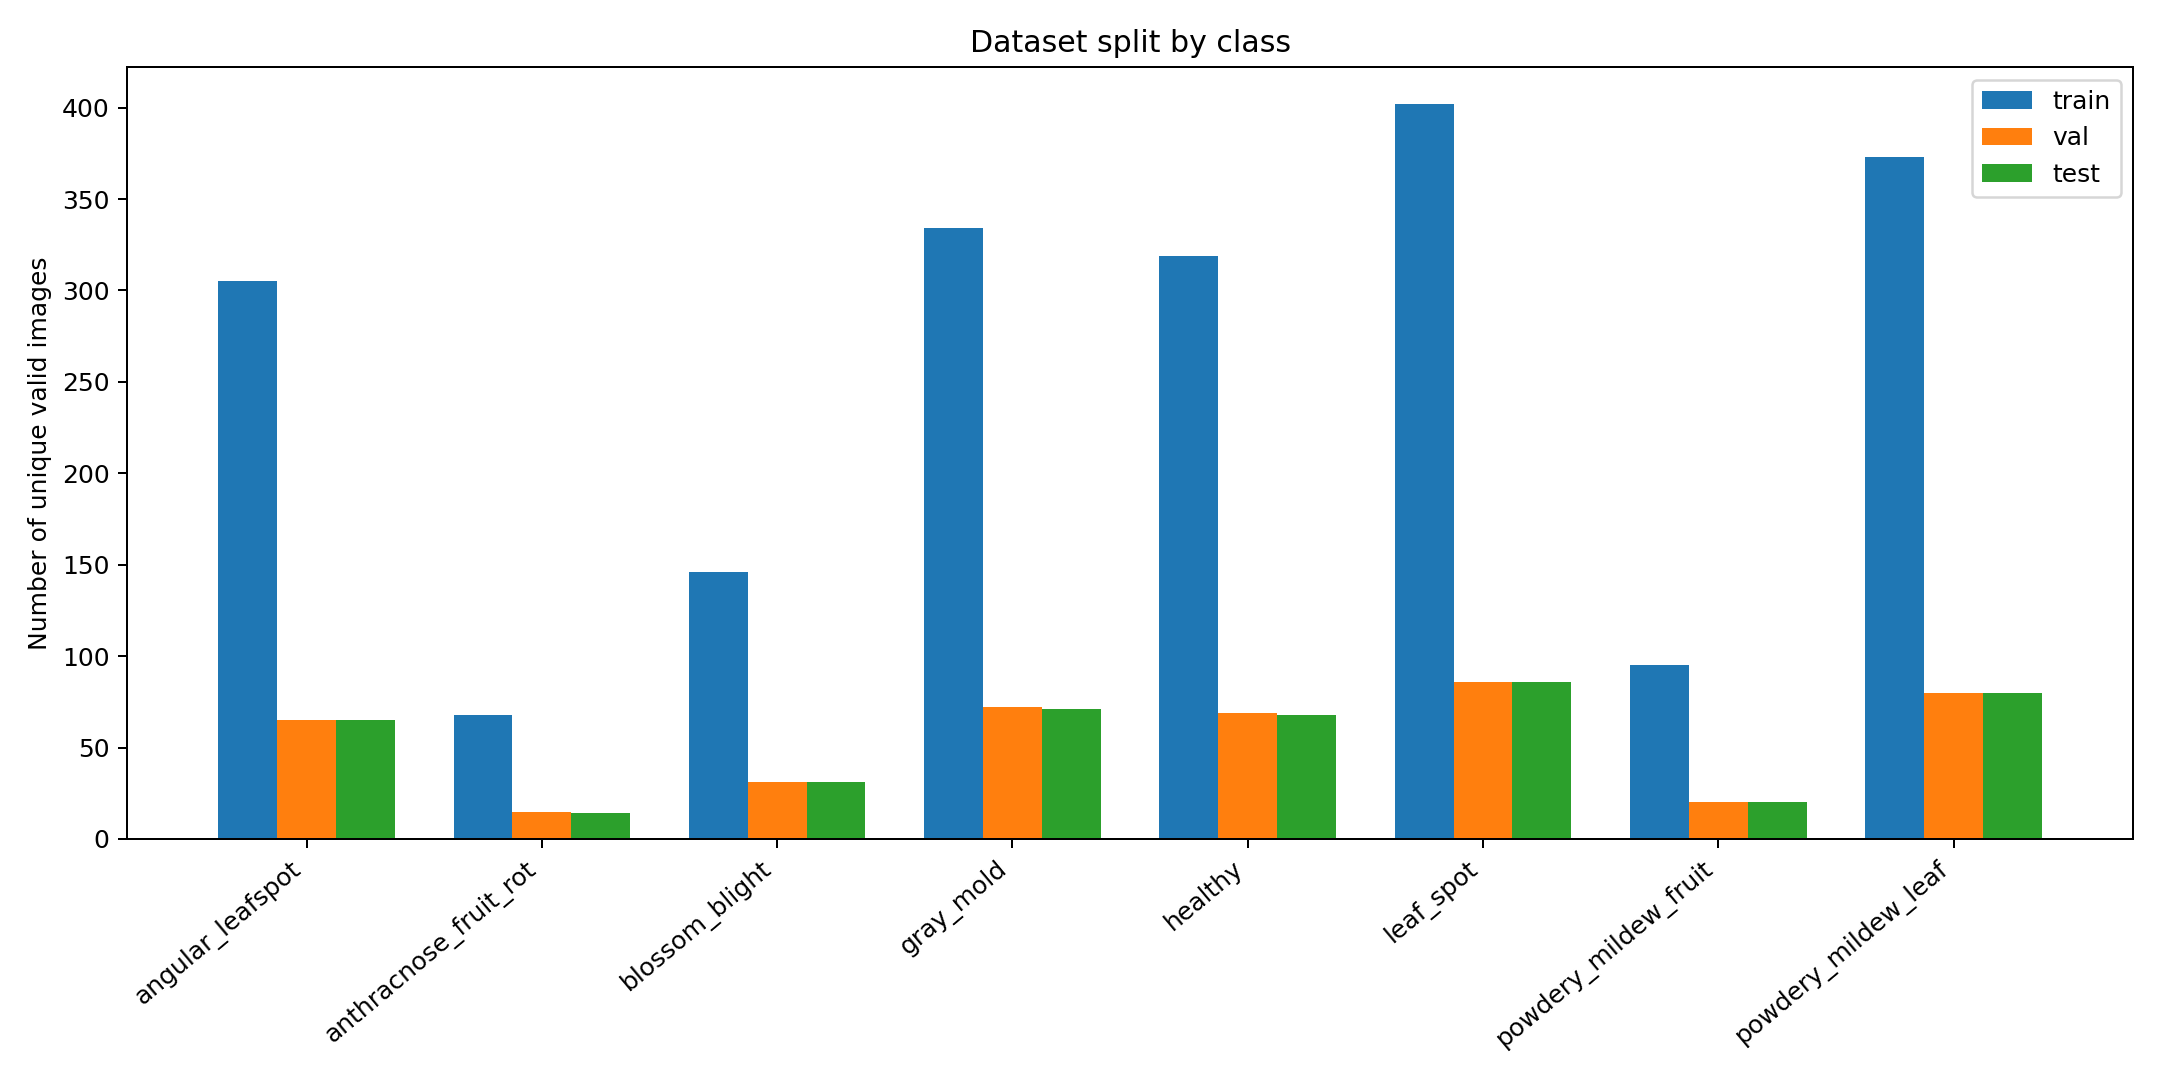

In [6]:
from IPython.display import display, Image as DisplayImage
records, class_names, split_info = pipeline.load_split(SPLIT_DIR)
for row in pipeline.read_csv(Path(SPLIT_DIR) / "split_counts.csv"):
    print(row)
print("Group-aware:", split_info["group_aware"])
print("Ảnh lỗi bị loại:", split_info["invalid_images_removed"])
print("Ảnh trùng bị loại:", split_info["exact_pixel_duplicates_removed"])
display(DisplayImage(filename=str(Path(SPLIT_DIR) / "split_distribution.png")))


## 6. Huấn luyện và đánh giá

Ảnh 224×224, MobileNetV3-Large ImageNet + GAP + Dropout + Dense(8, softmax).
Train head tối đa 10 epoch rồi fine-tune tối đa 15 epoch; BatchNorm giữ frozen/inference.
Checkpoint được chọn bằng **validation loss thấp nhất** giữa hai giai đoạn.

Test chỉ được dùng sau khi chốt model. Muốn tinh chỉnh siêu tham số thì dựa trên validation,
không chọn mô hình bằng cách so đi so lại điểm test. Số epoch thực tế có thể ít hơn nhờ EarlyStopping.

Giữ pixel đầu vào [0,255], không tự chia 255 vì backbone đã chuẩn hóa bên trong.

In [ ]:
train_command = [
    sys.executable, str(SCRIPT_PATH), "train",
    "--split-dir", SPLIT_DIR, "--output-dir", OUTPUT_DIR,
    "--image-size", str(IMAGE_SIZE), "--batch-size", str(BATCH_SIZE),
    "--head-epochs", str(HEAD_EPOCHS), "--finetune-epochs", str(FINETUNE_EPOCHS),
    "--seed", str(SEED),
]
if not EXPORT_TFLITE:
    train_command += ["--no-tflite"]
subprocess.run(train_command, check=True)


I0000 00:00:1790346293.998451     127 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13756 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1790346294.001373     127 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13756 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5


12683000/12683000 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Model: "strawberry_mobilenetv3_large"


2026-09-25 14:24:58.074192: E tensorflow/core/framework/node_def_util.cc:680] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_19}}


## 7. Đọc kết quả và biểu đồ

`accuracy`, `macro_f1` nằm trong khoảng 0–1. `classification_report` có precision, recall,
F1, support của từng lớp. Confusion matrix: hàng là nhãn thật, cột là dự đoán.

Các số liệu dưới đây là kết quả Keras trên test nội bộ. Không mặc định chúng là số đo
cho TFLite hoặc cho ảnh camera ngoài thực địa.

In [ ]:
import json
OUT = Path(OUTPUT_DIR)
metrics = json.loads((OUT / "evaluation/test_metrics.json").read_text(encoding="utf-8"))
print(json.dumps(metrics, indent=2, ensure_ascii=False))
print((OUT / "evaluation/classification_report.txt").read_text(encoding="utf-8"))
print("Checkpoint được chọn:")
print((OUT / "validation_selection.json").read_text(encoding="utf-8"))

for chart in [
    OUT / "plots/accuracy_curve.png",
    OUT / "plots/loss_curve.png",
    OUT / "evaluation/plots/confusion_matrix.png",
    OUT / "evaluation/plots/confusion_matrix_normalized.png",
    OUT / "evaluation/plots/per_class_scores.png",
    OUT / "evaluation/plots/roc_curves.png",
    OUT / "evaluation/plots/precision_recall_curves.png",
]:
    display(DisplayImage(filename=str(chart)))

if (OUT / "tflite_export_status.json").exists():
    print("Trạng thái chuyển đổi TFLite:")
    print((OUT / "tflite_export_status.json").read_text(encoding="utf-8"))


## 8. Dự đoán thử một ảnh

Điền đường dẫn ảnh mới vào `EXAMPLE_IMAGE`. Để trống sẽ dùng một ảnh test để kiểm tra
luồng suy luận, không phải phép kiểm tra trên dữ liệu ngoài thực địa.
Model chưa có lớp unknown và điểm softmax chưa được hiệu chuẩn.

In [ ]:
EXAMPLE_IMAGE = ""  # Ví dụ: "/content/anh_dau_moi.jpg"
if not EXAMPLE_IMAGE:
    example = next(row for row in records if row["split"] == "test")
    EXAMPLE_IMAGE = str(Path(SPLIT_DIR) / example["relative_path"])
subprocess.run([
    sys.executable, str(SCRIPT_PATH), "predict",
    "--model", str(OUT / "best_model.keras"),
    "--labels", str(OUT / "class_names.json"),
    "--image", EXAMPLE_IMAGE, "--top-k", "3",
], check=True)
display(DisplayImage(filename=EXAMPLE_IMAGE, width=320))


## 9. Đóng gói kết quả để lưu lại

ZIP này chứa model, nhãn, báo cáo và biểu đồ; không chứa bộ ảnh split để tránh sao chép
một bộ dữ liệu lớn lần nữa. Lưu thêm `manifest.csv` và `split_info.json` để tái lập thí nghiệm.

In [ ]:
import shutil
for name in ["manifest.csv", "split_info.json", "split_counts.csv", "duplicates.csv", "invalid_images.csv"]:
    shutil.copy2(Path(SPLIT_DIR) / name, OUT / name)
archive = shutil.make_archive(str(WORK_DIR / "strawberry_results"), "zip", root_dir=OUT)
print("Đã tạo:", archive)
try:
    from google.colab import files
    files.download(archive)
except ImportError:
    from IPython.display import FileLink
    display(FileLink(archive))


## Phạm vi kiểm thử của bộ code

Mã chia dữ liệu và xuất đánh giá đã qua 9 unit test với dữ liệu tổng hợp tạm thời.
Môi trường tạo file không có TensorFlow nên chưa kiểm thử runtime huấn luyện hay
chuyển TFLite ở đó. Không có bộ ảnh thật của bạn để huấn luyện/điền kết quả trước.

## Tài liệu API

- [MobileNetV3Large và preprocessing](https://www.tensorflow.org/api_docs/python/tf/keras/applications/MobileNetV3Large)
- [Học chuyển giao và BatchNorm](https://keras.io/guides/transfer_learning/)
- [Train/validation/test và nhóm](https://scikit-learn.org/stable/modules/cross_validation.html)
- [Classification report](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.classification_report.html)
- [Xuất TFLite FP16](https://ai.google.dev/edge/litert/models/post_training_float16_quant)
